# 03 · Results figures

**Team SPELUNCA · ExxonMobil DataWorks Challenge 2026**

## Purpose
Slide-ready figures for the four key messages of the project. They are built **only from the saved tables** in
`outputs/tables/`, so run `02_pipeline.ipynb` first; nothing is recomputed here. Each figure is shown here and saved
to `outputs/figures/` at 200 dpi.

| Figure | Key message | Research question |
|---|---|---|
| 1. Proxy accuracy | The ML proxy can stand in for the simulator | SRQ4 |
| 2. 2028 ranges | History matching narrows the forecast; the forecasting method is now the bigger uncertainty | SRQ6 (and SRQ5) |
| 3. Parameter influence | Porosity controls the history; the aquifer matters more for future water | SRQ3 (explains SRQ2) |
| 4. Business table | What the best 10 forecasts mean for the field to 2028 | Main question |

Each figure title states its finding and is **generated from the data**, so a title can never disagree with the
numbers. Under each figure you will find how to read it and the takeaway for the slide.

**Style.** Oil = blue, gas = orange, water = aqua in every figure (a palette validated for colour-blind readers);
every bar carries its value, so no reading depends on colour alone.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import load_config
from src.report import millions, pct, show_md, show_table, verdict

pd.set_option("display.max_columns", 50)
cfg = load_config(ROOT / "config.yaml", root=ROOT)   # data folder: DWC26_DATA_DIR in .env, else data/raw
print("Data folder:", cfg["paths"]["raw"])

Data folder: C:\SpeluncaDWC26trst\data\raw


In [2]:
from src.plotting import INK, INK_2, PHASE_COLORS, SLIDE_RC, clean_axes, plt

plt.rcParams.update(SLIDE_RC)
T, F = cfg["paths"]["tables"], cfg["paths"]["figures"]
PHASES = ["oil", "gas", "water"]


def save_and_show(fig, name):
    fig.savefig(F / name, dpi=200, bbox_inches="tight")
    display(Image(filename=str(F / name), width=1000))   # plt.show() draws nothing under the Agg backend
    plt.close(fig)
    print("saved", F / name)

## 1. Proxy accuracy vs baselines (SRQ4)

**Context.** History matching evaluates tens of thousands of parameter sets, so it needs a fast stand-in for the
simulator. This figure shows how closely each candidate model reproduces the simulator's 2008 cumulative for cases
it never saw. **How to read it:** shorter bars are better; the value is the mean absolute error in %. Validation
cases (71–85) were used to choose the model; test cases (86–100) are reported once, as the final check.

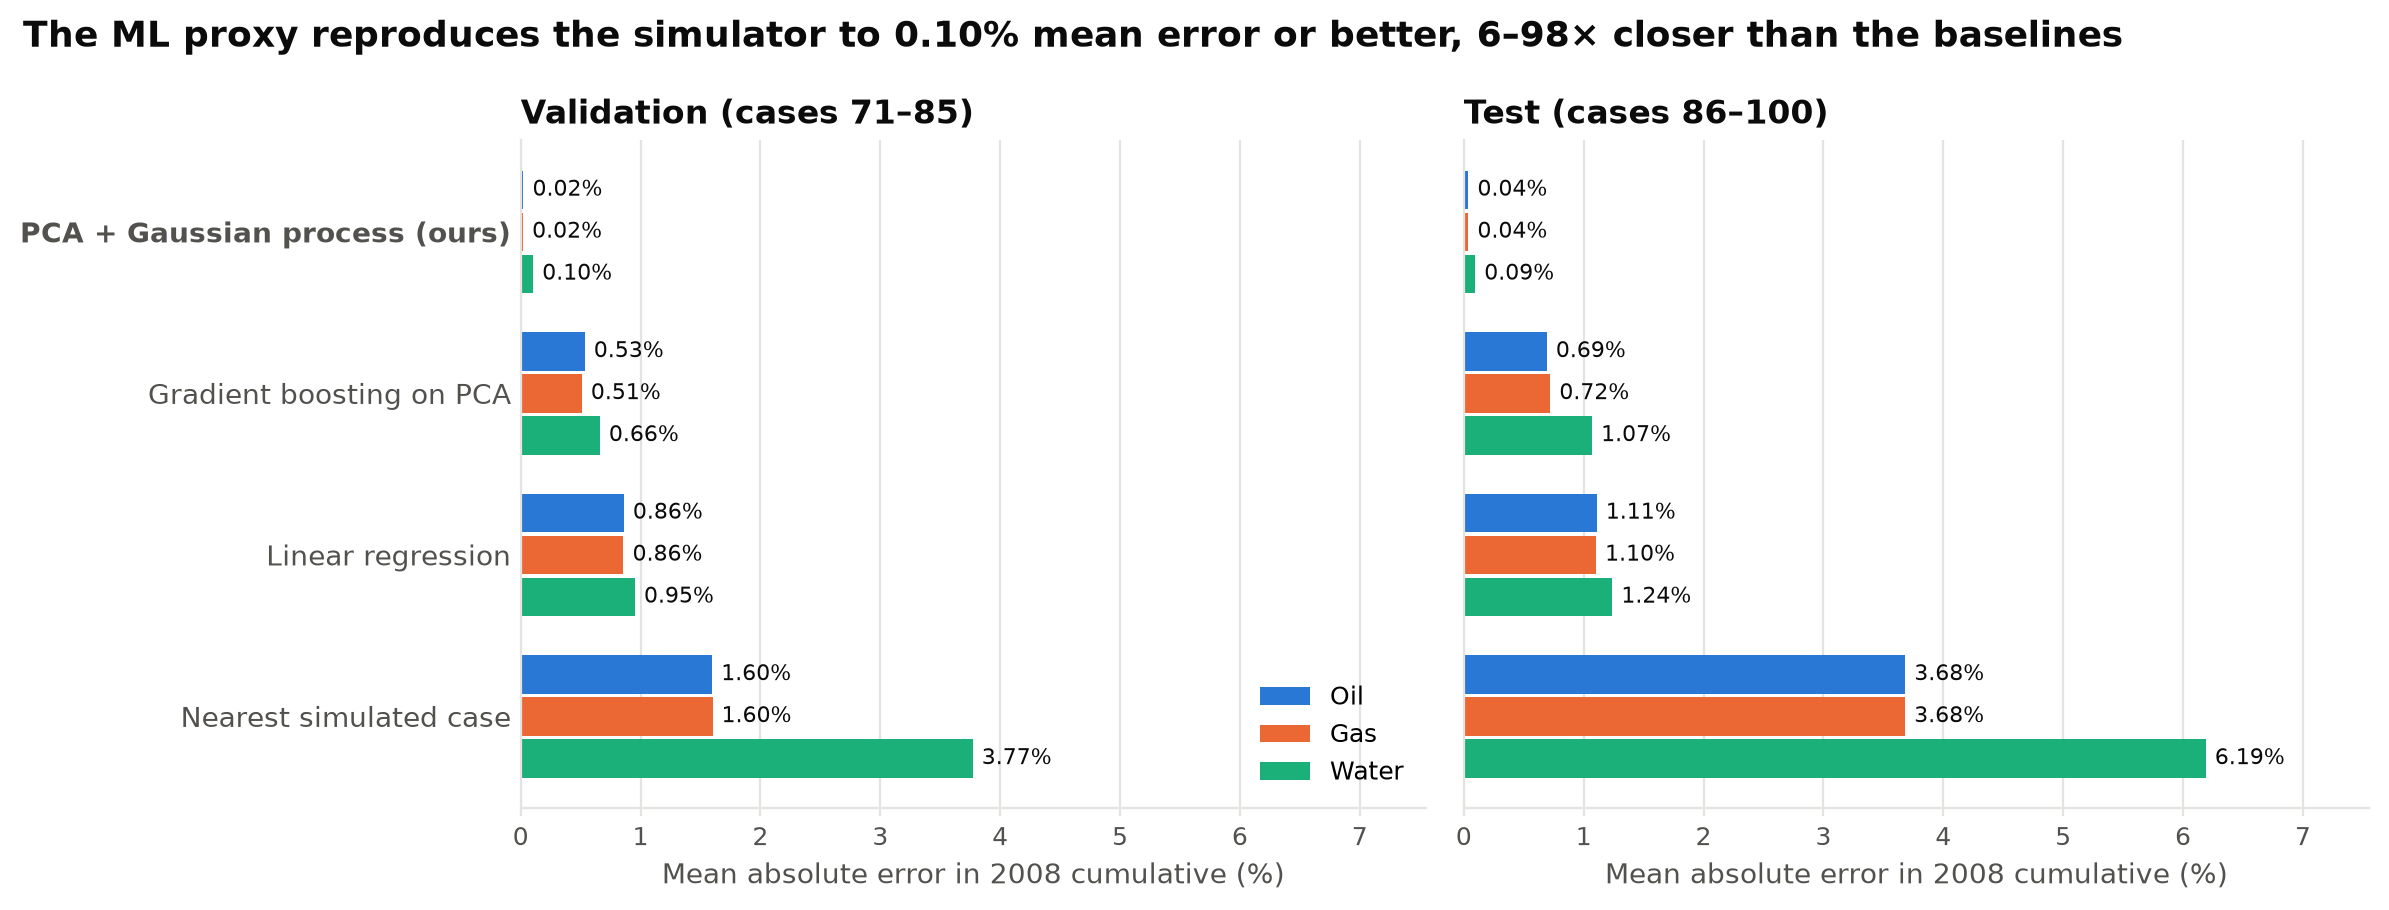

saved c:\speluncaDWC26\outputs\figures\slide_proxy_accuracy.png


In [3]:
MODEL_NAMES = {"pca_gp": "PCA + Gaussian process (ours)", "gboost_pca": "Gradient boosting on PCA",
               "linear": "Linear regression", "nearest_case": "Nearest simulated case"}
scores = pd.read_csv(T / "srq4_proxy_scores.csv")
order = list(MODEL_NAMES)[::-1]                         # ours on top after barh
splits = [("validation", "Validation (cases 71–85)"), ("test", "Test (cases 86–100)")]
xmax = scores["mape_end_2008"].max() * 1.22
piv = scores.pivot_table(index=["split", "model"], columns="phase", values="mape_end_2008")
ours_max = float(piv.xs("pca_gp", level="model").max().max())
ratios = (piv.drop(index="pca_gp", level="model") / piv.xs("pca_gp", level="model").reindex(
    piv.drop(index="pca_gp", level="model").index, level="split"))
r_lo, r_hi = float(ratios.min().min()), float(ratios.max().max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
h = 0.26
for ax, (split, title) in zip(axes, splits):
    v = scores[scores.split == split].pivot(index="model", columns="phase", values="mape_end_2008").loc[order]
    y = np.arange(len(order))
    for j, ph in enumerate(PHASES):
        yy = y + (1 - j) * h
        ax.barh(yy, v[ph], height=h * 0.92, color=PHASE_COLORS[ph], label=ph.capitalize())
        for yi, val in zip(yy, v[ph]):
            ax.text(val + xmax * 0.01, yi, f"{val:.2f}%", va="center", fontsize=8, color=INK)
    ax.set_yticks(y, [MODEL_NAMES[m] for m in order])
    ax.set_xlim(0, xmax)
    ax.set_xlabel("Mean absolute error in 2008 cumulative (%)")
    ax.set_title(title)
    clean_axes(ax, "x")
axes[0].get_yticklabels()[-1].set_fontweight("bold")
axes[0].legend(loc="lower right", title=None)
fig.suptitle(f"The ML proxy reproduces the simulator to {ours_max:.2f}% mean error or better, {r_lo:.0f}–{r_hi:.0f}× closer than the baselines",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
save_and_show(fig, "slide_proxy_accuracy.png")

In [4]:
best_base = piv.drop(index="pca_gp", level="model").groupby("split").min()
ours = piv.xs("pca_gp", level="model")
val_max, test_max = float(ours.loc["validation"].max()), float(ours.loc["test"].max())
water_hardest = bool((piv.idxmax(axis=1) == "water").all())
show_md(f"""**Takeaway for the slide.** On cases it never saw, our proxy's error is at most **{ours_max:.2f}%** (any
phase, validation or test), against **{best_base.min().min():.2f}–{best_base.max().max():.2f}%** for the best
baseline. {"Water is the hardest phase for every model. " if water_hardest else ""}The largest test error ({test_max:.3f}%)
is {"of the same size as" if test_max <= 2 * val_max else "clearly larger than"} the largest validation error ({val_max:.3f}%),
so the model choice {"did not over-fit" if test_max <= 2 * val_max else "may have over-fitted"} the validation cases.
*Caveat to say aloud:* this is accuracy against the simulator, not against the real field. Figure 2's backtest
covers the real field.""")

**Takeaway for the slide.** On cases it never saw, our proxy's error is at most **0.10%** (any
phase, validation or test), against **0.51–1.07%** for the best
baseline. Water is the hardest phase for every model. The largest test error (0.094%)
is of the same size as the largest validation error (0.104%),
so the model choice did not over-fit the validation cases.
*Caveat to say aloud:* this is accuracy against the simulator, not against the real field. Figure 2's backtest
covers the real field.

## 2. Did history matching narrow the 2028 forecast? (SRQ6, SRQ5)

**Context.** Before matching, all 100 simulated cases are equally plausible; after matching, only parameter sets
that reproduce 1998–2008 remain. This figure compares the 2028 cumulative ranges before and after, and against the
second forecasting method. **How to read it:** each bar runs from P90 (low case) to P10 (high case); the tick is
P50. A shorter bar means less uncertainty. The ranges show **parameter uncertainty only**; the horizontal gap
between the two "Best 10" rows is **model-form uncertainty** (how we extrapolate).

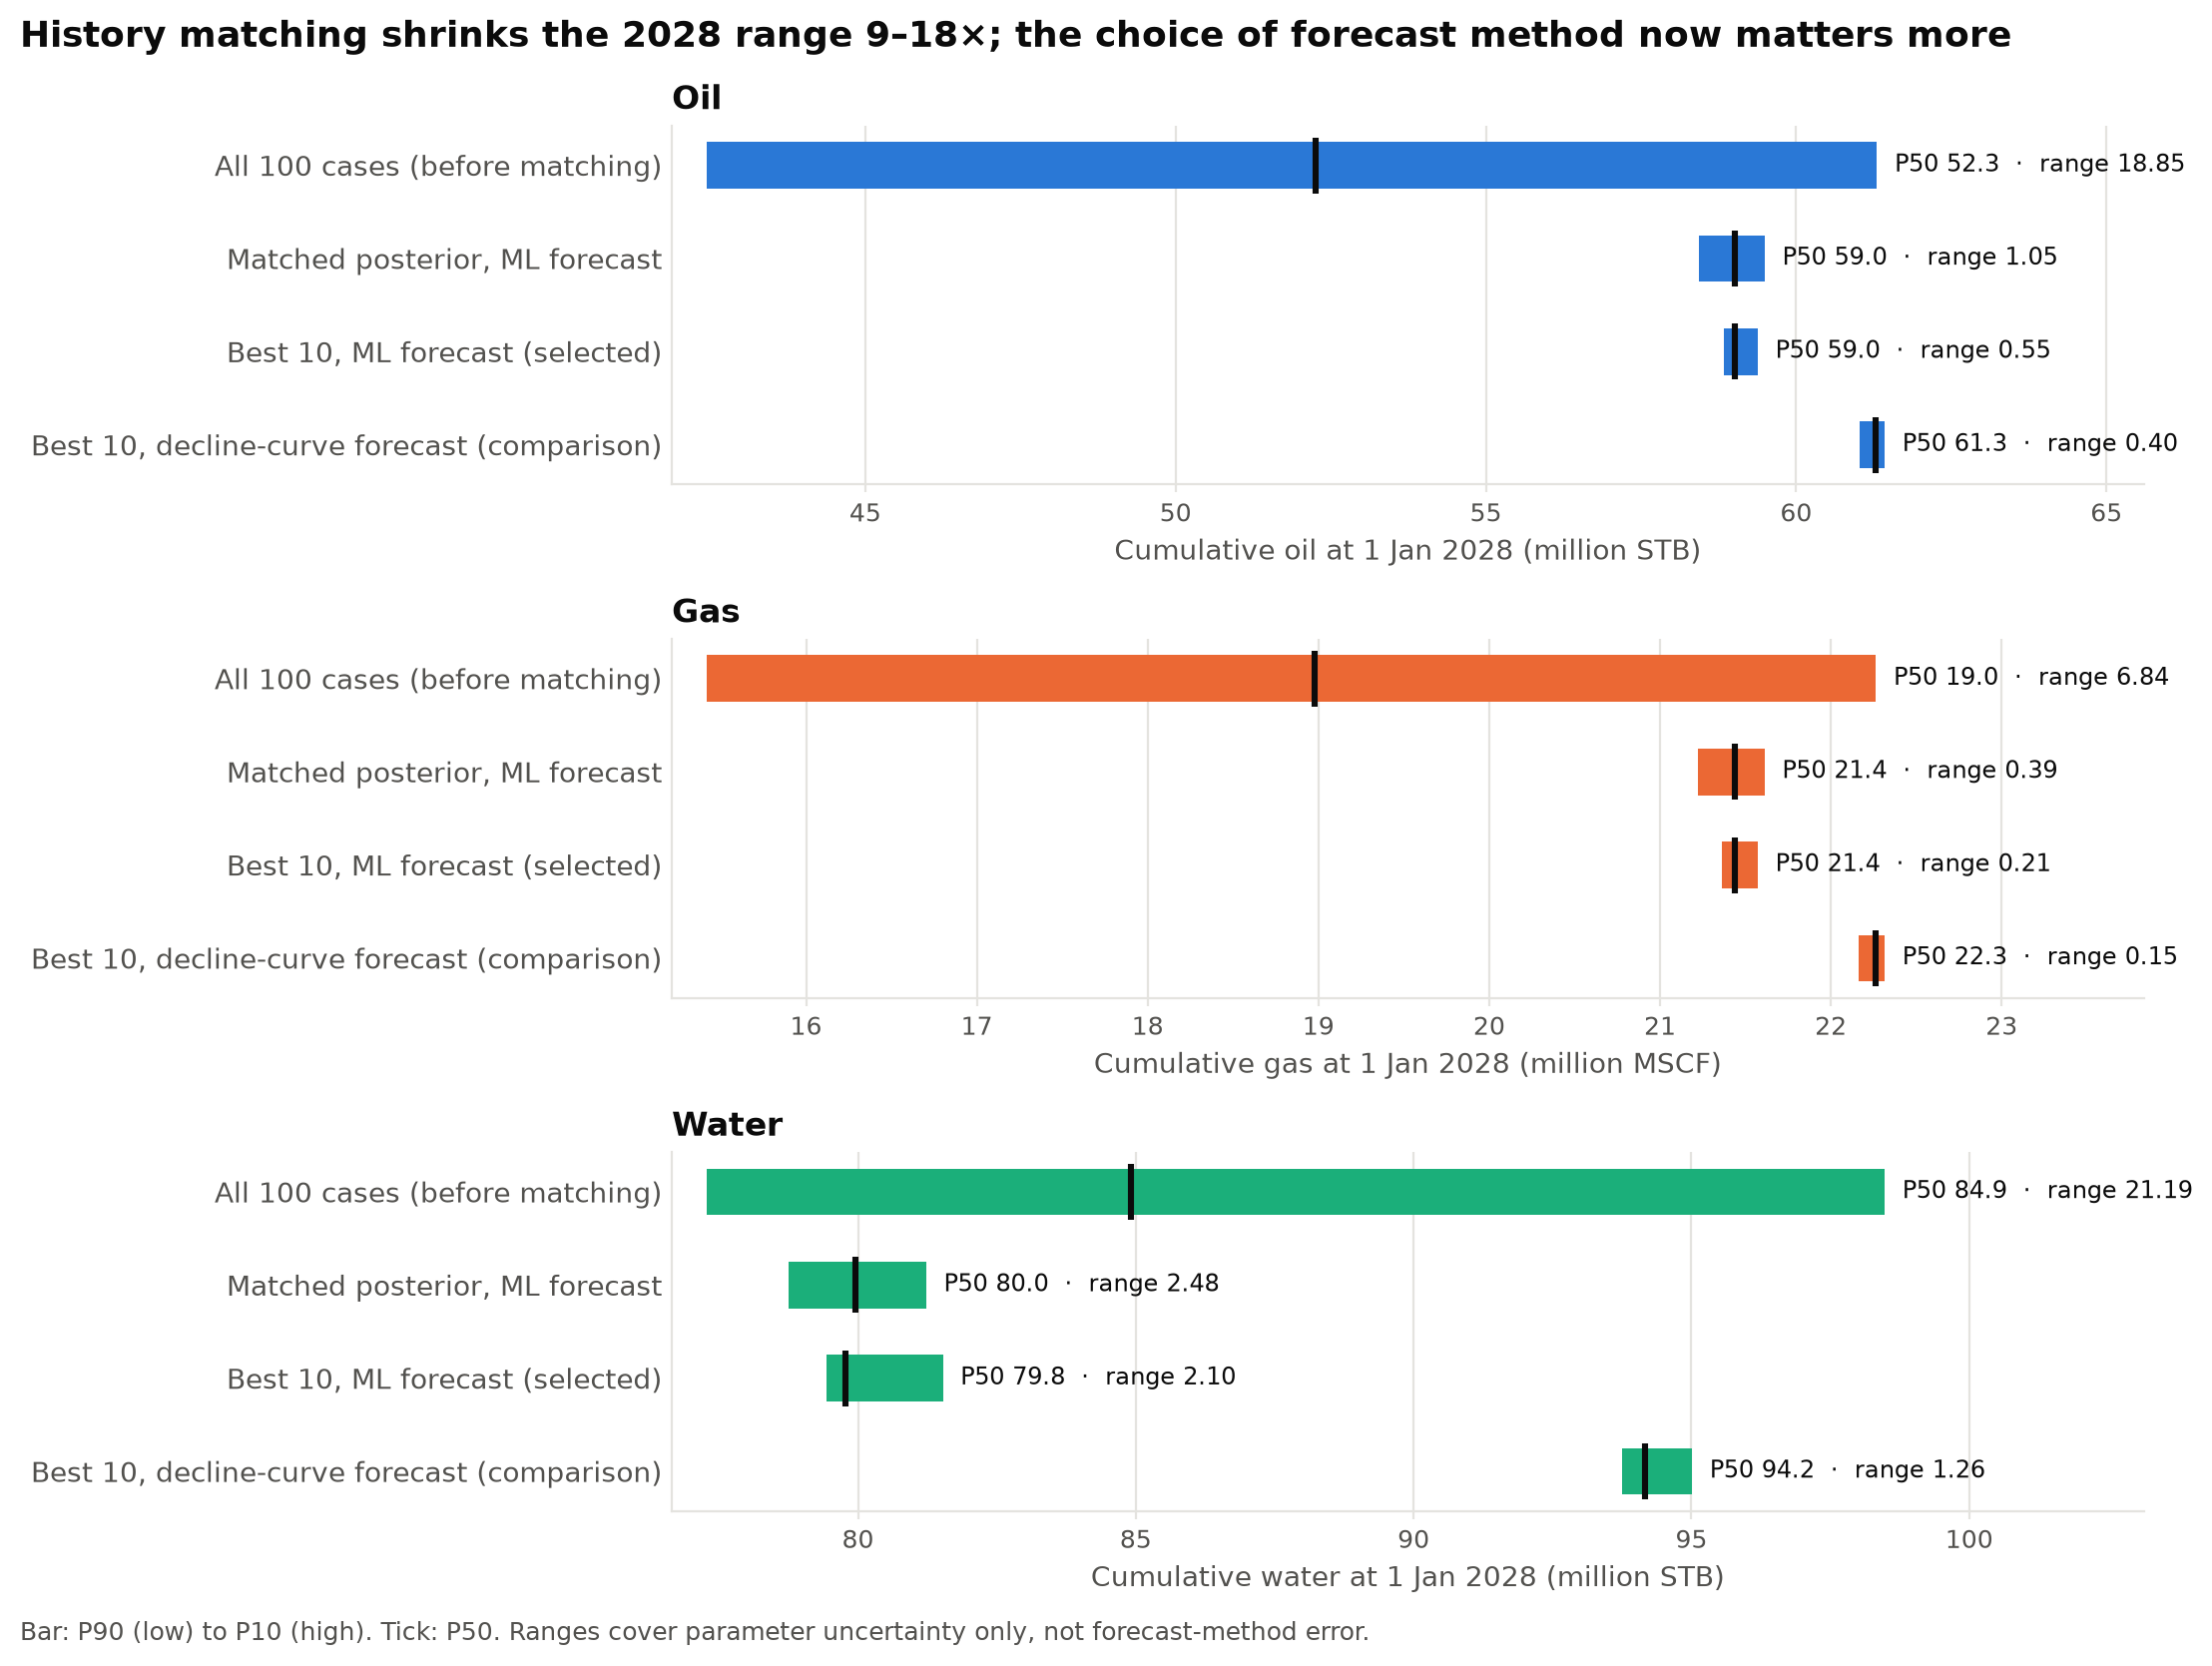

saved c:\speluncaDWC26\outputs\figures\slide_spread_2028.png


In [5]:
sel = pd.read_csv(T / "srq5_method_selection.csv")
chosen = sel.loc[sel.selected.astype(bool), "method"].item()
other = sel.loc[~sel.selected.astype(bool), "method"].item()
METHOD = {"ml_autoregressive": "ML forecast", "decline": "decline-curve forecast"}
ROWS = [("all_100_cases", "All 100 cases (before matching)"),
        ("posterior", f"Matched posterior, {METHOD[chosen]}"),
        ("best_10", f"Best 10, {METHOD[chosen]} (selected)"),
        (f"best_10_{other}", f"Best 10, {METHOD[other]} (comparison)")]
UNITS = {"oil": "million STB", "gas": "million MSCF", "water": "million STB"}

sp = pd.read_csv(T / "srq6_spread_2028.csv")
spi = sp.set_index(["phase", "set"])
narrow = {k: spi.loc[(k, "all_100_cases"), "P10_P90_width"] / spi.loc[(k, "posterior"), "P10_P90_width"] for k in PHASES}
gap = {k: abs(spi.loc[(k, "best_10"), "P50"] - spi.loc[(k, f"best_10_{other}"), "P50"]) for k in PHASES}
method_dominates = all(gap[k] > spi.loc[(k, "posterior"), "P10_P90_width"] for k in PHASES)

fig, axes = plt.subplots(3, 1, figsize=(11, 8.2))
for ax, ph in zip(axes, PHASES):
    cols = ["P90_low", "P50", "P10_high"]
    d = sp[sp.phase == ph].set_index("set").reindex([k for k, _ in ROWS])[cols] / 1e6
    y = np.arange(len(ROWS))[::-1]                      # first row at the top
    ax.barh(y, d["P10_high"] - d["P90_low"], left=d["P90_low"], height=0.5, color=PHASE_COLORS[ph])
    ax.plot(d["P50"], y, "|", color=INK, ms=20, mew=2.2)
    lo, hi = d["P90_low"].min(), d["P10_high"].max()
    pad = (hi - lo) * 0.22
    ax.set_xlim(lo - (hi - lo) * 0.03, hi + pad)
    for yi, (_, r) in zip(y, d.iterrows()):
        ax.text(r["P10_high"] + (hi - lo) * 0.015, yi, f"P50 {r['P50']:.1f}  ·  range {r['P10_high'] - r['P90_low']:.2f}",
                va="center", fontsize=8.5, color=INK)
    ax.set_yticks(y, [lab for _, lab in ROWS])
    ax.set_xlabel(f"Cumulative {ph} at 1 Jan 2028 ({UNITS[ph]})")
    ax.set_title(ph.capitalize())
    clean_axes(ax, "x")
fig.suptitle(f"History matching shrinks the 2028 range {min(narrow.values()):.0f}–{max(narrow.values()):.0f}×"
             + ("; the choice of forecast method now matters more" if method_dominates else ""),
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.text(0.01, -0.01, "Bar: P90 (low) to P10 (high). Tick: P50. Ranges cover parameter uncertainty only, "
         "not forecast-method error.", fontsize=9, color=INK_2)
fig.tight_layout()
save_and_show(fig, "slide_spread_2028.png")

In [6]:
pbt = pd.read_csv(T / "srq6_pipeline_backtest.csv").set_index(["phase", "set"])
show_md(f"""**Takeaway for the slide.**
- Matching the history cuts the P10–P90 range by **{min(narrow.values()):.0f}–{max(narrow.values()):.0f}×**
  (oil: {spi.loc[('oil', 'all_100_cases'), 'P10_P90_width'] / 1e6:.1f} → {spi.loc[('oil', 'posterior'), 'P10_P90_width'] / 1e6:.2f} million STB).
- {"After matching, the difference between the two forecasting methods (" + ", ".join(f"{k} {gap[k] / 1e6:.1f} M" for k in PHASES) +
   ") is larger than the parameter range. The main remaining uncertainty is *how* we extrapolate, which is why both "
   "methods are shown." if method_dominates else "Parameter uncertainty remains larger than the difference between methods."}
- Tested against the real field (match to 2004, forecast 2004–2008), the selected method's P50 was within
  **{pct(pbt.loc[('oil', 'best_10'), 'p50_rel_err_2008'])}** for oil and **{pct(pbt.loc[('water', 'best_10'), 'p50_rel_err_2008'])}**
  for water.

*Caveat to say aloud:* the bars are not full confidence intervals, because they leave out forecasting-method error.""")

**Takeaway for the slide.**
- Matching the history cuts the P10–P90 range by **9–18×**
  (oil: 18.9 → 1.05 million STB).
- After matching, the difference between the two forecasting methods (oil 2.3 M, gas 0.8 M, water 14.4 M) is larger than the parameter range. The main remaining uncertainty is *how* we extrapolate, which is why both methods are shown.
- Tested against the real field (match to 2004, forecast 2004–2008), the selected method's P50 was within
  **0.8%** for oil and **5.7%**
  for water.

*Caveat to say aloud:* the bars are not full confidence intervals, because they leave out forecasting-method error.

## 3. Which parameters matter, in history vs in the forecast (SRQ3)

**Context.** The Sobol total index is the share of an output's variance caused by one parameter (including its
interactions): 1 means it explains everything, 0 means nothing. Comparing the 2008 cumulative (what the history
shows) with the 2028 cumulative (what the forecast needs) shows whether a parameter the history cannot pin down
becomes important later. **How to read it:** hatched bars = cumulative at 2008, solid bars = cumulative at 2028.
Gas is not shown: it follows oil exactly (constant gas–oil ratio), so its indices equal oil's.

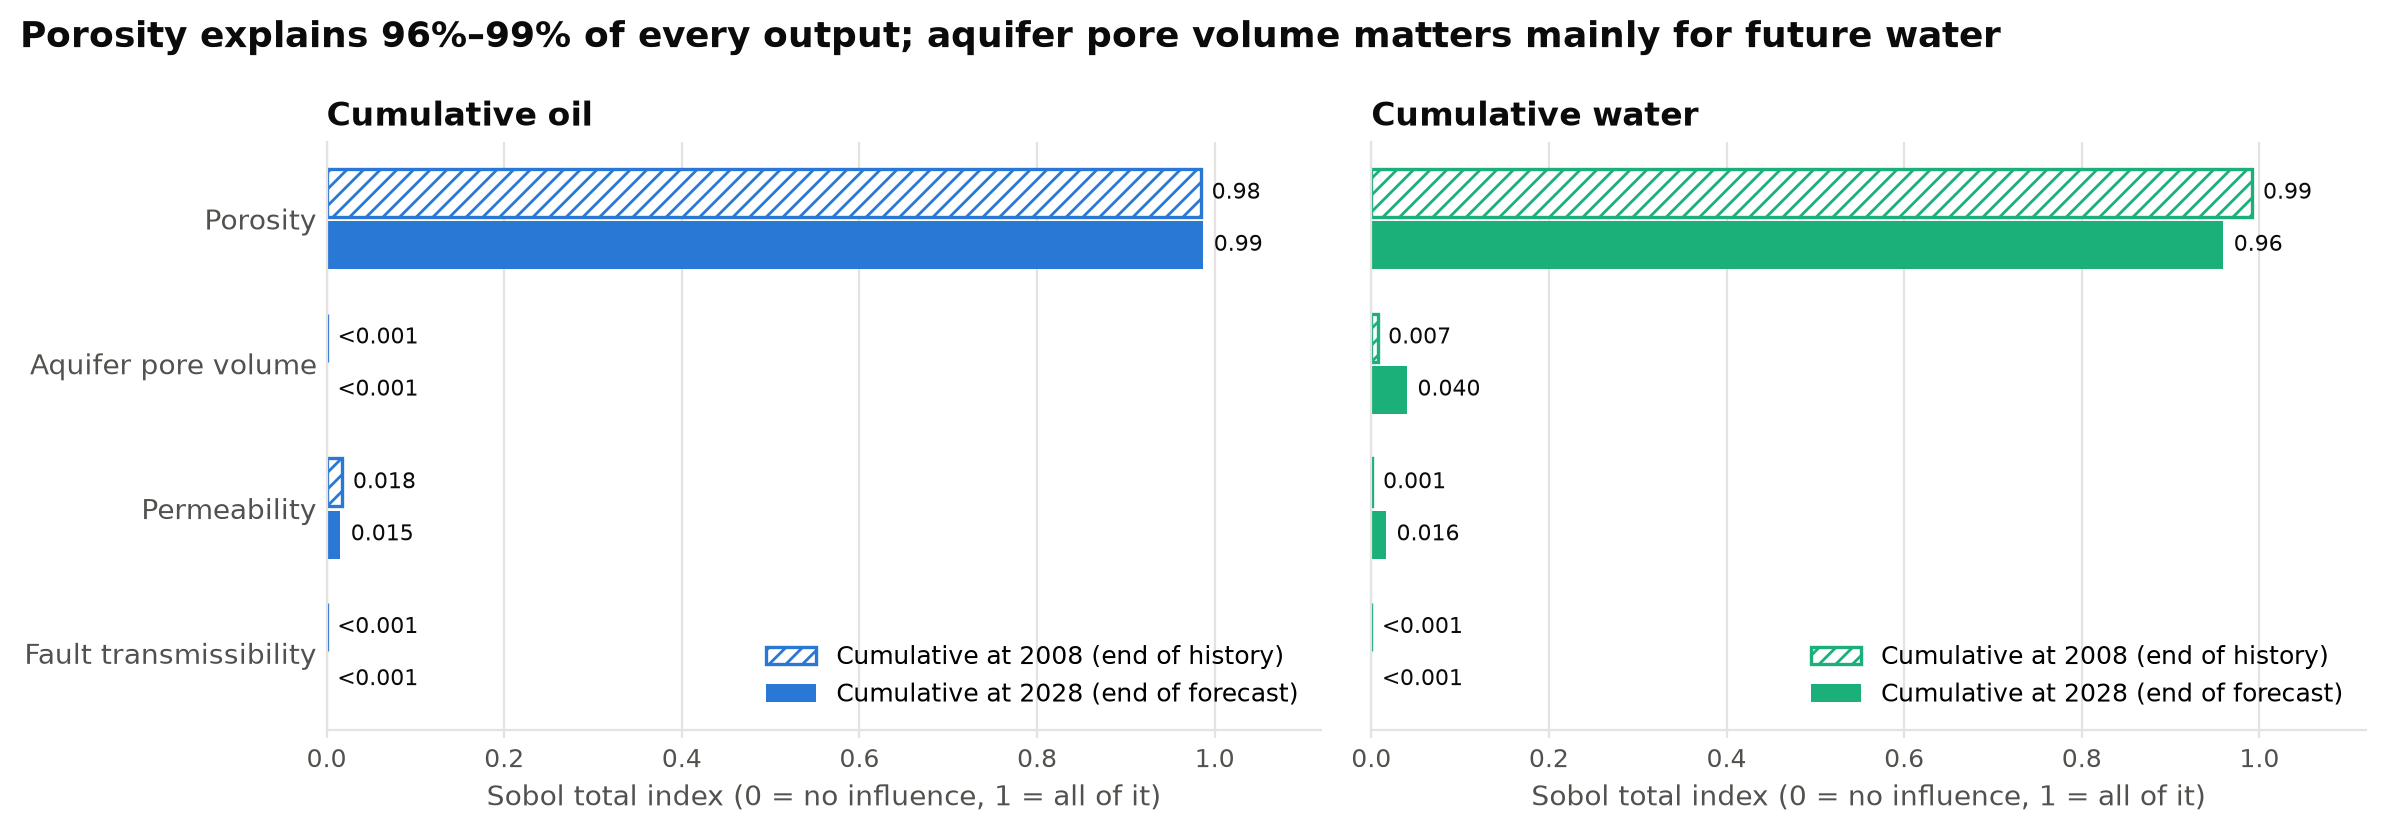

saved c:\speluncaDWC26\outputs\figures\slide_sobol.png


In [7]:
PARAM_NAMES = {"Porosity Multiplier": "Porosity", "Permeability Multiplier": "Permeability",
               "Aquifer Pore Volume": "Aquifer pore volume", "Fault Transmissibility": "Fault transmissibility"}
sob = pd.read_csv(T / "srq3_sobol.csv")
st = sob.pivot(index="parameter", columns="outcome", values="ST").clip(lower=0)
params = st.max(axis=1).sort_values().index.tolist()   # most influential on top after barh
top = params[-1]
others = st.drop(index=top)
riser = others["cum_water_2028"].idxmax()            # most important secondary parameter for future water


def fmt(v):
    return "<0.001" if v < 0.001 else (f"{v:.3f}" if v < 0.1 else f"{v:.2f}")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
h = 0.36
for ax, ph in zip(axes, ("oil", "water")):
    y = np.arange(len(params))
    c = PHASE_COLORS[ph]
    hist, fcst = st.loc[params, f"cum_{ph}_2008"], st.loc[params, f"cum_{ph}_2028"]
    ax.barh(y + h / 2, hist, height=h * 0.92, facecolor="white", edgecolor=c, hatch="////", lw=1.2,
            label="Cumulative at 2008 (end of history)")
    ax.barh(y - h / 2, fcst, height=h * 0.92, color=c, label="Cumulative at 2028 (end of forecast)")
    for yi, a, b in zip(y, hist, fcst):
        ax.text(a + 0.012, yi + h / 2, fmt(a), va="center", fontsize=8, color=INK)
        ax.text(b + 0.012, yi - h / 2, fmt(b), va="center", fontsize=8, color=INK)
    ax.set_yticks(y, [PARAM_NAMES.get(p, p) for p in params])
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("Sobol total index (0 = no influence, 1 = all of it)")
    ax.set_title(f"Cumulative {ph}")
    ax.legend(loc="lower right")
    clean_axes(ax, "x")
fig.suptitle(f"{PARAM_NAMES[top]} explains {pct(st.loc[top].min(), 0)}–{pct(st.loc[top].max(), 0)} of every output; "
             f"{PARAM_NAMES[riser].lower()} matters mainly for future water",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
save_and_show(fig, "slide_sobol.png")

In [8]:
show_md(f"""**Takeaway for the slide.**
- **{PARAM_NAMES[top]}** controls almost all of the produced volumes, which is why the history pins it down
  precisely while the other parameters stay uncertain (non-uniqueness, SRQ2).
- **{PARAM_NAMES[riser]}**'s influence on water grows from {fmt(st.loc[riser, 'cum_water_2008'])} at 2008 to
  {fmt(st.loc[riser, 'cum_water_2028'])} at 2028: a parameter the history hardly constrains matters more for future
  water handling. That is a reason to report a range of forecasts rather than one.
- Fault transmissibility's total index is {"below 0.001" if st.loc['Fault Transmissibility'].max() < 0.001
  else f"at most {st.loc['Fault Transmissibility'].max():.3f}"} for every output, so it has no practical effect.""")

**Takeaway for the slide.**
- **Porosity** controls almost all of the produced volumes, which is why the history pins it down
  precisely while the other parameters stay uncertain (non-uniqueness, SRQ2).
- **Aquifer pore volume**'s influence on water grows from 0.007 at 2008 to
  0.040 at 2028: a parameter the history hardly constrains matters more for future
  water handling. That is a reason to report a range of forecasts rather than one.
- Fault transmissibility's total index is below 0.001 for every output, so it has no practical effect.

## 4. Business view: the best 10 forecasts (template sheets Case 1–10)

**Context.** The Kick Off deck frames the forecast as a business question: will the field keep producing enough to
be worth running? This table summarises each of the 10 deliverable forecasts (Case 1 = best match).
**How to read it:** "Oil 2008–2028" is the oil still to be produced; "Oil / HCPV" is cumulative oil per reservoir
barrel of initial hydrocarbon pore volume. The oil formation volume factor is not in the data, so this stands in for
a recovery factor (recovery factor = this × Bo); "WOR cap reached" flags a forecast that hit the water–oil-ratio
safety limit.

In [9]:
b = pd.read_csv(T / "srq6_business.csv")
biz = pd.DataFrame({
    "Oil 2008–2028 (M STB)": b["oil_2008_2028_stb"].to_numpy() / 1e6,
    "Cum. oil 2028 (M STB)": b["cum_oil_2028"].to_numpy() / 1e6,
    "HCPV (M rb)": b["hcpv_rb"].to_numpy() / 1e6,
    "Oil / HCPV 2028 (STB/rb)": b["np_2028_per_hcpv_stb_per_rb"].to_numpy(),
    "Oil rate 2028 (STB/d)": b["oil_rate_2028_stb_d"].to_numpy(),
    "Water cut 2028 (%)": 100 * b["water_cut_2028"].to_numpy(),
    "WOR cap reached": b["wor_cap_reached"].astype(bool).to_numpy(),
}, index=pd.Index(b["template_sheet"], name="Sheet"))
show_table(biz, title="Business view: the 10 deliverable forecasts (Case 1 = best match)",
           formats={"Oil 2008–2028 (M STB)": "{:.2f}", "Cum. oil 2028 (M STB)": "{:.2f}", "HCPV (M rb)": "{:.1f}",
                    "Oil / HCPV 2028 (STB/rb)": "{:.3f}", "Oil rate 2028 (STB/d)": "{:,.0f}",
                    "Water cut 2028 (%)": "{:.1f}"})

Sheet,Oil 2008–2028 (M STB),Cum. oil 2028 (M STB),HCPV (M rb),Oil / HCPV 2028 (STB/rb),Oil rate 2028 (STB/d),Water cut 2028 (%),WOR cap reached
Case 1,20.53,58.91,168.5,0.350,"1,083",90.2,No
Case 2,20.67,59.04,169.4,0.349,"1,102",90.2,No
Case 3,20.63,59.01,170.1,0.347,"1,101",89.8,No
Case 4,21.06,59.44,173.1,0.343,"1,164",89.9,No
Case 5,20.53,58.91,170.6,0.345,"1,092",89.9,No
Case 6,20.95,59.33,171.8,0.345,"1,141",90.1,No
Case 7,20.51,58.89,173.5,0.339,"1,082",90.0,No
Case 8,20.39,58.77,172.2,0.341,"1,076",90.1,No
Case 9,20.64,59.02,171.5,0.344,"1,098",89.9,No
Case 10,20.67,59.05,171.0,0.345,"1,103",89.8,No


In [10]:
obs_end = None
try:
    from src import io_load
    obs = io_load.load_observed(cfg)
    obs_end = obs.iloc[-1]
except Exception:                                    # data folder not available: skip the comparison
    pass
show_md(f"""**Takeaway for the slide.**
- The best 10 forecasts expect **{b.oil_2008_2028_stb.min() / 1e6:.2f}–{b.oil_2008_2028_stb.max() / 1e6:.2f} million STB**
  of additional oil from 2008 to 2028, i.e. a cumulative of {b.cum_oil_2028.min() / 1e6:.1f}–{b.cum_oil_2028.max() / 1e6:.1f}
  million STB by 2028.
- In 2028 the field still produces **{b.oil_rate_2028_stb_d.min():,.0f}–{b.oil_rate_2028_stb_d.max():,.0f} STB/d** of oil
  {f"(down from {obs_end['oil']:,.0f} STB/d in 2008)" if obs_end is not None else ""}, with a water cut of
  **{100 * b.water_cut_2028.min():.1f}–{100 * b.water_cut_2028.max():.1f}%**. The field becomes mainly a
  water-handling operation, so water treatment and injection capacity drive operating cost.
- {int(b.wor_cap_reached.sum())} of 10 forecasts reach the WOR safety cap.

*Caveat:* economics (oil price, costs) are not in the data; this table gives the volumes an economic evaluation needs.""")

**Takeaway for the slide.**
- The best 10 forecasts expect **20.39–21.06 million STB**
  of additional oil from 2008 to 2028, i.e. a cumulative of 58.8–59.4
  million STB by 2028.
- In 2028 the field still produces **1,076–1,164 STB/d** of oil
  (down from 5,067 STB/d in 2008), with a water cut of
  **89.8–90.2%**. The field becomes mainly a
  water-handling operation, so water treatment and injection capacity drive operating cost.
- 0 of 10 forecasts reach the WOR safety cap.

*Caveat:* economics (oil price, costs) are not in the data; this table gives the volumes an economic evaluation needs.